In [33]:
import geopandas as gpd
from shapely.geometry import Polygon, MultiPolygon
from shapely.geometry import Point
import pandas as pd

In [62]:
dict_pontos = {
    "id": [1,2,3],
    "nm_sitio": ['Sítio Arqueológico Santana VII', 'Sítio Arqueológico Santana VIII', 'Sítio Arqueológico Santana X'],
    'coord_E': [[782127, 782173,782200,782196, 782127],[782714,782755,782819,782796,782768,782737],[[783852,783881,783898,783909,783960,783980,783930,783897,783896,783853]]],
    'coord_N': [[9329044, 9329043, 9328949,9328947, 9329044],[9327909,9327945,9327931,9327904,9327868,9327863],[[9325274,9325262,9325257,9325211,9325230,9325239,9325274,9325285,9325269,9325286]]],
}
crs = 'EPSG:32724'
geometries = []
for coord_E, coord_N in zip(dict_pontos['coord_E'], dict_pontos['coord_N']):
    # A lista pode representar um único anel ou vários anéis/componentes.
    if not coord_E and not coord_N:
        geometries.append(None)
        continue
    if not coord_E or not coord_N:
        raise ValueError('As coordenadas E e N não podem estar vazias separadamente.')
    east_rings = coord_E if coord_E and isinstance(coord_E[0], (list, tuple)) else [coord_E]
    north_rings = coord_N if coord_N and isinstance(coord_N[0], (list, tuple)) else [coord_N]

    if len(east_rings) != len(north_rings):
        raise ValueError('Cada sítio deve ter o mesmo número de anéis de coordenadas E e N.')

    polygons = []
    for east_ring, north_ring in zip(east_rings, north_rings):
        if len(east_ring) != len(north_ring):
            raise ValueError('Cada anel deve ter o mesmo número de coordenadas E e N.')
        if len(east_ring) < 3:
            raise ValueError('Cada anel precisa ter pelo menos 3 vértices.')
        polygons.append(Polygon(zip(east_ring, north_ring)))

    if not polygons:
        geometries.append(None)
    elif len(polygons) == 1:
        geometries.append(polygons[0])
    else:
        geometries.append(MultiPolygon(polygons))
dict_pontos['geometry'] = geometries
gdf = gpd.GeoDataFrame(dict_pontos, geometry='geometry', crs=crs).to_crs("EPSG:4674")
gdf

,id,nm_sitio,coord_E,coord_N,geometry
0,1,Sítio Arqueológico Santana VII,"[782127, 782173, 782200, 782196, 782127]","[9329044, 9329043, 9328949, 9328947, 9329044]","POLYGON ((-36.45125 -6.06412, -36.45084 -6.064..."
1,2,Sítio Arqueológico Santana VIII,"[782714, 782755, 782819, 782796, 782768, 782737]","[9327909, 9327945, 9327931, 9327904, 9327868, ...","POLYGON ((-36.4459 -6.07435, -36.44554 -6.0740..."
2,3,Sítio Arqueológico Santana X,"[[783852, 783881, 783898, 783909, 783960, 7839...","[[9325274, 9325262, 9325257, 9325211, 9325230,...","POLYGON ((-36.43552 -6.09812, -36.43525 -6.098..."


<Axes: >

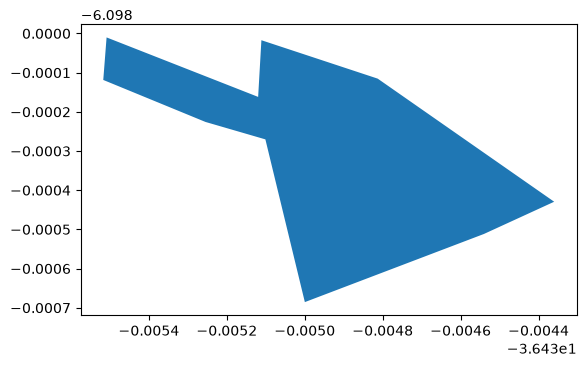

In [63]:
gdf[2:].plot()

In [64]:
# gdf.to_file(r'C:\Users\larissa.valadao\OneDrive - IPHAN - Instituto do Patrimônio Histórico e Artístico Nacional\Documentos\arquivos_analise\CORA\01421.0025372014-20\danos_sitos_arq.shp')
gdf.to_file(r'C:\Users\larissa.valadao\OneDrive - IPHAN - Instituto do Patrimônio Histórico e Artístico Nacional\Documentos\arquivos_analise\CORA\01421.0025372014-20\danos_sitos_arq.kml',driver='KML')

In [65]:
gdf.geometry = gdf.geometry.centroid
# gdf.to_file(r'C:\Users\larissa.valadao\OneDrive - IPHAN - Instituto do Patrimônio Histórico e Artístico Nacional\Documentos\arquivos_analise\CORA\01421.0025372014-20\danos_sitos_arq_pt.shp')
# gdf.geometry = gdf.geometry.centroid
gdf.to_file(r'C:\Users\larissa.valadao\OneDrive - IPHAN - Instituto do Patrimônio Histórico e Artístico Nacional\Documentos\arquivos_analise\CORA\01421.0025372014-20\danos_sitos_arq_pt.kml',driver='KML')

C:\Users\larissa.valadao\AppData\Local\Temp\ipykernel_3448\2463804466.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf.geometry = gdf.geometry.centroid


In [ ]:

# gdf_N = gdf_N.loc[gdf_N['fuso_zona'] == '22N'].copy()
# gdf_N = gdf_N.to_crs("EPSG:4674")
# gdf_S = gpd.GeoDataFrame(dict_pontos, geometry=gpd.points_from_xy(dict_pontos['coord_E'], dict_pontos['coord_N']),crs='EPSG:31982')
# gdf_S = gdf_S.loc[gdf_S['fuso_zona'] == '22S'].copy()
# gdf_S = gdf_S.to_crs("EPSG:4674")

# gdf = pd.concat([gdf_N, gdf_S], ignore_index=True)
gdf
# gdf.to_file('sitios_pontos.shp')

In [ ]:
# pts = gpd.read_file(r"C:\Users\larissa.valadao\OneDrive - IPHAN - Instituto do Patrimônio Histórico e Artístico Nacional\Documentos\arquivos_analise\DBGEO\ADA_v.shp")
# pts.geometry = pts.force_2d()
# poly = gpd.GeoDataFrame(pts[0:1],geometry=pts.dissolve().convex_hull).to_crs('EPSG:4674')
# poly